# Video Conferencing QoE Inference over Multiple Streams

## Setup: Clone the Data Repository

Before starting, you need to clone the course data repository to access the datasets:

```bash
git clone https://github.com/noise-courses/data.git
```

This repository contains the Microsoft Teams video conference data needed for this assignment in the `data/video-conference-qoe/` directory.

In this notebook, you will explore a packet trace captured for a Microsoft Teams call for 3 participants. The trace was captured for one of the participants, and no participants were sharing their screens. Each of the participants joined the conference call from their laptops connected to campus WiFi.

## Background

1. The Secure Real Time Transport Protocol (SRTP) is a variant of the Real Time Transport Protocol (RTP), which is used for delivering audio and video over IP networks. SRTP is intended to provide additional security to RTP with the help of features like encryption and message authentication.

2. Video conferencing can either use the peer-to-peer mode or the Selective Forwarding Unit (SFU) mode. In peer-to-peer mode, each participant can directly transfer their audio and/or video to other participants on the call. The SFU mode requires an additional server which collects audiovisual streams from each participant and relays them to other participants on the call. SFU is the most common architecture nowadays as it can scale to large group meetings.

3. Inferring the mode/architecture from a packet trace is often a prerequisite to estimating videoconferencing quality. This is typically done using the information provided by the IP layer.

## Learning Objectives

In this hands-on activity, you will learn how to:

- Identify a participant's video stream from Secure Real Time Transport Protocol (SRTP) headers. 
- Compare the frame rate for one participant's video stream with that for other participants.
- Predict individual frame rate for each participant.

### Step 1: Inspecting the Trace

Load the packet trace `teams.csv` provided in `data/video-conference-qoe/` as a pandas DataFrame.

First, verify that the data file exists:

```python
import os
assert os.path.exists('data/video-conference-qoe/teams.csv'), "teams.csv not found in data/video-conference-qoe/ directory"
```

In [29]:
import os
import pandas as pd

DATA_PATH = 'data/video-conference-qoe/teams.csv'
assert os.path.exists(DATA_PATH)

df = pd.read_csv(DATA_PATH)
df['Time'] = pd.to_datetime(df['Time'])
print(f"Loaded {len(df):,} packets from {DATA_PATH}")
df.head()

Loaded 211,388 packets from data/teams.csv


,No.,Time,Source,Destination,Protocol,Length,Info
0,1,2022-11-16 18:19:03.665510627,10.150.89.79,52.114.159.102,TLSv1.2,195,Application Data
1,2,2022-11-16 18:19:03.721051945,52.114.159.102,10.150.89.79,TLSv1.2,161,Application Data
2,3,2022-11-16 18:19:03.767528493,10.150.89.79,52.114.159.102,TCP,54,36678 > 443 [ACK] Seq=142 Ack=108 Win=501 Len=0
3,4,2022-11-16 18:19:03.779969802,10.150.89.79,128.135.249.50,DNS,85,Standard query 0xed7f AAAA 204.pop-os.org OPT
4,5,2022-11-16 18:19:03.782992016,128.135.249.50,10.150.89.79,DNS,309,Standard query response 0xed7f AAAA 204.pop-os...


In [30]:
srtp = df[df['Protocol'] == 'SRTP']
print('Sources:', list(srtp['Source'].unique()))
print('Destinations:', list(srtp['Destination'].unique()))

Sources: ['10.150.89.79', '52.115.174.113']
Destinations: ['52.115.174.113', '10.150.89.79']


**Question:** After examining the trace, identify whether the call was conducted in peer-to-peer mode or the SFU mode. Write a brief justification for your answer.

The call was conducted in SFU mode. All of the SRTP media traffic in the trace flows between two IP addresses: the captured participant's laptop and a server. If the call were peer-to-peer, we would see media flows to/from the other two participants' addresses, which is not the case. Instead, we see multiple participants' video streams over one server connection, which indicates SFU. 

Filter out all SRTP traffic that contained audio. In this packet trace, assume that SRTP video used either `102` or `107` as the payload type. Your resulting DataFrame should contain only video packets.

In [31]:
video = srtp[srtp['Info'].str.contains('PT=DynamicRTP-Type-102|PT=DynamicRTP-Type-107')]
print(len(video), 'video packets')
video.head()

178219 video packets


,No.,Time,Source,Destination,Protocol,Length,Info
751,752,2022-11-16 18:19:13.414399787,52.115.174.113,10.150.89.79,SRTP,110,"PT=DynamicRTP-Type-102, SSRC=0x3E9, Seq=16566,..."
752,753,2022-11-16 18:19:13.415101290,52.115.174.113,10.150.89.79,SRTP,859,"PT=DynamicRTP-Type-102, SSRC=0x3E9, Seq=16567,..."
753,754,2022-11-16 18:19:13.415101385,52.115.174.113,10.150.89.79,SRTP,860,"PT=DynamicRTP-Type-102, SSRC=0x3E9, Seq=16568,..."
799,800,2022-11-16 18:19:13.536586093,10.150.89.79,52.115.174.113,SRTP,118,"PT=DynamicRTP-Type-107, SSRC=0x117AA4FC, Seq=2..."
800,801,2022-11-16 18:19:13.536695591,10.150.89.79,52.115.174.113,SRTP,1251,"PT=DynamicRTP-Type-107, SSRC=0x117AA4FC, Seq=2..."


Using the filtered trace you obtained above, find the total duration of the conference call in minutes.

In [32]:
duration = video['Time'].max() - video['Time'].min()
print(duration.total_seconds() / 60, 'minutes')

5.1439409305999995 minutes


Recall that the trace was captured for only one participant. Find the IP address of the participant for which the packets were captured.

**Hint:** Find the participant that sends less video traffic compared to the video traffic that it receives.

In [33]:
sent = video.groupby('Source')['Length'].sum()
received = video.groupby('Destination')['Length'].sum()
print('Bytes sent:', sent.to_dict())
print('Bytes received:', received.to_dict())

ip_A = (sent - received).idxmin()  # sends less than it receives
print('Participant A IP:', ip_A)

Bytes sent: {'10.150.89.79': 90271647, '52.115.174.113': 118180491}
Bytes received: {'10.150.89.79': 118180491, '52.115.174.113': 90271647}
Participant A IP: 10.150.89.79


Take a look at the RTP header format below. The field `SSRC Identifier` allows us to separate each participant's video packets from each other. SSRC stands for Synchronization Source. It is a 32-bit value that uniquely identifies the source of RTP packets without making use of IP addresses.

![RTP Header Format](./images/rtp_header.png)

Extract the SSRC Identifier field for each video packet in the trace using the `Info` column. Use this field to identify the participants. Label each packet with its corresponding participant by adding a new column `Participant` to your DataFrame. For keeping the analysis consistent for the rest of the notebook, you should assign the label `A` to the participant for which we captured the traffic. Use `B` and `C` for the other participants.

**Note:** You will notice that there are more SSRCs than the total number of participants. Only consider the SSRCs that appeared for at least 5 seconds during the call. Discard the rest of the streams.

In [34]:
video = video.copy()
video['SSRC'] = video['Info'].str.extract(r'SSRC=(0x[0-9A-Fa-f]+)')

# how long each SSRC shows up for
ssrc_times = video.groupby('SSRC')['Time'].agg(['min', 'max', 'count'])
ssrc_times['seconds'] = (ssrc_times['max'] - ssrc_times['min']).dt.total_seconds()
print(ssrc_times)

# keep only SSRCs that last at least 5 seconds
keep = ssrc_times[ssrc_times['seconds'] >= 5].index
video = video[video['SSRC'].isin(keep)].copy()

# A = the stream sent by the captured laptop, B and C = the other two
ssrc_A = video[video['Source'] == ip_A]['SSRC'].unique()[0]
others = sorted(s for s in video['SSRC'].unique() if s != ssrc_A)
labels = {ssrc_A: 'A', others[0]: 'B', others[1]: 'C'}
print(labels)

video['Participant'] = video['SSRC'].map(labels)
video['Participant'].value_counts()

                                     min                           max  count  \
SSRC                                                                            
0x117AA4FC 2022-11-16 18:19:13.536586093 2022-11-16 18:24:22.050855623  75989   
0x3E9      2022-11-16 18:19:13.414399787 2022-11-16 18:24:21.986674310  51759   
0x44D      2022-11-16 18:19:14.979347502 2022-11-16 18:24:22.019659435  50410   
0x609FA917 2022-11-16 18:19:17.592567161 2022-11-16 18:19:18.588675871     61   

               seconds  
SSRC                    
0x117AA4FC  308.514270  
0x3E9       308.572275  
0x44D       307.040312  
0x609FA917    0.996109  
{'0x117AA4FC': 'A', '0x3E9': 'B', '0x44D': 'C'}


Participant
A    75989
B    51759
C    50410
Name: count, dtype: int64

### Step 2: Inspecting Ground-Truth Frame Rate

Below are three dictionaries representing the ground-truth frame rates per 1-second window for each participant (A, B, and C). A is the participant for which the packets were captured.

**Note:** Participant A's ground truth starts at 18:19:08.662 and has 310 values, while participants B and C start at 18:19:10.663 (2 seconds later) and have 308 values each. This 2-second offset reflects when each participant's video stream became active in the call. You will need to account for this timing difference when aligning your features with the ground truth labels.

In [35]:
FPS_A = {
     "startTime": "2022-11-16 18:19:08.662000",
     "endTime": "2022-11-16 18:24:17.071000",
     "values": [0,0,0,0,0,2.0072949401791456,7.000881306011575,9.836331839037307,14.64617107020074,14.620603831791582,16.33933125901901,21.998311172438257,30.022217980530634,30.001888394006734,30.000057220568124,30.00147349918862,28.997248433857756,30.17821864102032,30.021530333338422,29.995830638584543,30.00299722095384,28.989971054077277,30.00725444698554,29.976500812846986,30.017376468197057,29.976743620933885,30.02701806215443,30.00387718711744,29.9994564154893,29.999341979155044,28.998465142426106,29.989053430366067,30.00963758989181,30.00032902124762,29.999513633983824,30.00546554939264,29.998855634474392,29.999370588156758,28.975254687716628,30.0253127827644,29.97883621834695,30.0168107720622,30.005637274306334,29.995766283597973,30.000786801945736,30.002789756776128,29.999220391506512,29.999249000276322,29.001071731118756,28.980639516848036,31.02488320042759,29.990075534619795,30.002668141178287,29.99600940388504,30.00726875902633,30.00038624307087,28.995852110084044,30.00231045395771,29.993256654494957,30.00473574043755,30.00654601802981,29.99555891940857,30.003147455425356,29.996795996521367,28.959684467885975,30.04268990321712,30.001051462785014,29.999277609100695,29.994121749859243,30.056030297493006,29.922559916836846,28.999101189814883,30.174688964163007,30.769532863114296,30.000543604210357,30.010568048717488,29.555694888856703,30.005308136615128,28.976504065912206,31.024135531005303,29.998018872445186,29.998920002717874,28.992030188844744,28.983850655798292,30.025499064366166,30.001344741061047,30.002939989169967,29.986173329539458,29.038139355913515,30.433423548277087,30.197949990520325,29.84397443024957,29.878656142062216,29.271146741954123,29.984351218982138,30.015307126508617,29.99879841848986,30.00203861737393,30.001559338554337,28.99796738567081,30.864058761486607,29.00839158259715,29.99967098596922,29.99976396746375,29.995494565587922,30.00486452767344,30.004227757121196,28.993453788581423,29.97682217733357,30.02843688757836,29.97628657368386,30.018944775300078,29.99447924185402,30.0036911737074,30.00035763213196,30.000872637381974,30.00203861737393,28.979251696385326,28.989300861898847,31.033887673746527,29.98039335752018,30.017140162155236,28.991366811478724,29.99480814201567,31.01575817601039,29.999370588156758,28.98541159537367,30.018343213476214,30.001530725377854,28.979306930480767,31.017341534113285,29.999642376394554,30.003777025763895,29.997182157094503,29.44620792641831,30.015967279957543,30.007326007326007,29.55398453190018,30.002546526566377,30.00870718876093,30.00038624307087,30.00032902124762,29.9982048155287,30.002517911506857,28.984755427724465,30.011584461985578,30.004077511830747,29.985966097962784,28.773473496196992,30.96584811961076,30.021530333338422,30.00296860503461,29.99972820528226,29.992984981949974,29.52768618905079,28.633460871634444,29.831860234574158,29.99415034890523,30.012300287292923,30.17310329468349,29.609796910280917,30.27864586153252,29.153849934786418,30.00435653999635,30.00380564322524,30.000422006821253,29.99148372242131,30.001738172143895,30.01122656213665,29.987073748269825,28.982697326158355,30.021766708507673,28.987131586309978,31.01578777000641,29.997511116536007,28.97559980904447,31.028673920659177,29.998254877521966,28.9516541039124,30.035525856918376,30.01113350957415,29.997182157094503,28.98901759410929,31.012088958131443,28.99089693754512,31.014611452157368,29.995887843248877,30.00045061788295,29.003194684015277,29.998254877521966,29.999105956972926,29.9605983113562,30.050244895804948,29.972359398328607,29.010215780426904,29.998140450354317,29.99525860394134,30.01323807011359,29.997031982356862,30.004471014591246,30.00389865035163,29.99648850539776,28.99802960433072,31.006453665268367,28.981185015011818,29.002558457047726,31.014818595997422,28.987684237167684,31.011164393003806,30.44689963559285,28.12798175904503,30.138877411779752,30.013717722147312,29.52404550061944,30.491028824982802,30.56115065977864,30.0081060371733,28.97244570590952,30.011978161678947,30.010381952336513,29.98180063619143,30.01789205793019,29.999306217979637,30.00375556270371,29.980450503319126,30.023686499268074,29.994207547160816,28.99646730547116,30.012214386453074,29.998047478923382,29.998920002717874,29.9981118436988,27.988075568427853,27.992945541515976,31.02451306254608,29.99592359627488,28.98324290179328,30.018851674869442,29.999370588156758,30.002639525886785,29.994264745634556,30.003490854152876,29.996881809122854,29.999213239322586,29.002461642347498,30.004657037670977,29.996703033423803,29.998405064504293,29.997847234721743,30.00473574043755,29.99876981057944,30.00030041041785,29.99844082353126,30.00359816786729,28.996633205325367,30.0009012493032,29.987409632596254,31.012836047024162,30.003719791004972,30.000393395814125,30.000150204456876,28.996432743240472,30.000028610256777,28.983802310796616,31.014604054214256,30.005308136615128,30.023850245451065,29.303118782408824,26.992599132298913,30.011076246745578,30.005551411603786,30.001380507096737,29.557254765195502,30.031285366141542,29.55013636181099,30.48273838636072,29.995208551948117,29.997954508068727,29.997389543728005,29.001970663461467,29.987252409208864,30.016574474926934,30.000779649014888,29.995194251409306,30.00598073003061,30.001258902923325,29.997897295521526,28.97661451336676,30.02428827526998,30.00018596764449,30.001888394006734,30.238181384775494,29.744472743056615,30.000543604210357,30.000536451395476,30.000028610256777,28.999426137836114,29.98911060918384,30.008492489000425,28.9837401531743,30.006052284296157,31.015980132357125,30.001587951785396,29.999012979557232,30.0007510373256,28.9986932866499,30.004020275925413,29.99864822756886,29.53890070919211,30.24200502795176]
}

FPS_B = {
     "startTime": "2022-11-16 18:19:10.663000",
     "endTime": "2022-11-16 18:24:17.071000",
     "values": [0,0,0,3.010942410268718,7.000881306011575,9.836331839037307,15.772799614062334,14.620603831791582,15.17223616908908,14.99884852666245,15.011108990265317,26.00163660813917,27.00005149851131,30.00147349918862,27.99734331544887,27.66336708760196,27.01937730000458,28.995969617298393,29.00289731358871,28.989971054077277,29.007012632086024,28.977284119085418,30.017376468197057,27.97829404620496,28.0252168580108,29.003747947546856,26.99951077394037,27.999385847211375,25.99862392079582,28.98941831602053,29.009316336895417,26.00028515174794,29.999513633983824,28.00510117943313,28.998893779991914,29.999370588156758,29.974401401086165,29.02446902333892,29.97883621834695,30.0168107720622,29.00544936516279,28.99590740747804,30.000786801945736,30.002789756776128,27.999272365406078,29.999249000276322,29.001071731118756,28.980639516848036,30.024080516542828,25.991398796670488,26.002312389021185,23.996807523108032,27.006541883123695,31.0003991178399,29.995709079397287,28.00215642369386,29.993256654494957,30.00473574043755,30.00654601802981,25.996151063487428,28.002937625063666,29.996795996521367,29.95829427712342,30.04268990321712,26.00091126774701,27.999325768493982,27.994513633201958,28.177528403899693,25.647908500145867,30.999039202905564,26.998405915303742,29.487468993817867,28.000507363929668,27.00951124384574,30.18453946096004,30.005308136615128,28.976504065912206,24.018685572391202,28.998084910030347,27.99899200253668,29.991755367770423,25.98552127761226,28.023799126741757,29.001299916359013,29.002841989530967,29.986173329539458,30.566462479908964,25.140654235533248,28.939702074248647,27.8543761348996,29.878656142062216,17.158948090111036,27.985394471049993,39.0198992644612,27.99887852392387,25.00169884781161,32.001663294457956,28.99796738567081,28.993509745638935,26.8596218357381,27.99969292023794,26.999787570717373,25.9960952901762,30.00486452767344,28.00394590664645,28.993453788581423,26.979139959600214,25.0236974063153,25.979448363859348,29.018313282790075,25.995215342940153,26.003199017213078,26.000309947847697,31.000901725294707,29.001970663461467,26.98068261387599,30.988562990305663,29.031701372214496,27.981700467018836,25.014283468462697,27.99166450763463,27.995154265881293,29.01474151949359,25.999454509735855,27.98591464380906,27.01650889212859,28.00142867701933,28.979306930480767,29.016222725460818,27.99966621796825,30.003777025763895,28.997276085191352,29.44620792641831,27.61468989756094,29.007081807081807,28.925176350370393,28.00237675812862,27.007836469884836,29.00037336830184,28.000307086497777,25.99844417345821,28.002350050739732,26.98580677753657,25.009653718321314,26.003533843586645,24.988305081635655,24.849818019442857,27.869263307649685,26.018659622226632,26.002572791029998,27.999746324930108,28.993218815884976,29.52768618905079,26.588213666517696,30.860545070249128,27.99454032564488,27.01107025856363,24.515646426930335,25.123464045086838,28.115885442851624,28.112641008544045,30.00435653999635,29.003678788451065,30.000422006821253,29.99148372242131,28.00162229400097,28.01047812466087,29.987073748269825,27.98329397008393,29.02104115155742,28.987131586309978,30.01527848710298,29.997511116536007,28.97559980904447,29.02682399029407,27.9983712190205,25.956655403507668,28.03315746645715,26.00964904163093,29.997182157094503,27.989396297760692,28.010919058957434,21.993094228482505,26.012254766325537,25.99643613081569,30.00045061788295,28.00308452249751,27.9983712190205,27.999165559841398,30.959284921734742,23.038521086783796,33.96867398477242,29.010215780426904,24.998450375295263,32.994784464335474,28.012355532106017,26.997328784121176,29.004321980771536,29.003768695339907,25.99695670467806,27.998097549008975,27.005620934266,29.980536222426018,27.002382011734092,28.013384538320253,27.98810891864466,26.009363684454804,27.297220362945314,25.96429085450311,27.124989670601778,30.013717722147312,29.52404550061944,30.491028824982802,27.39965231566361,31.00837623841241,26.974346002053693,28.011179617567016,28.009689822180743,25.984227218032572,30.01789205793019,27.999352470114328,26.003254821009882,29.980450503319126,29.02289694929247,24.995172955967348,31.996101854313004,28.011400094022868,24.99837289910282,26.999028002446085,25.998363597872295,27.988075568427853,27.992945541515976,30.02372231859298,29.99592359627488,29.982665070820634,29.01822328570713,29.999370588156758,30.002639525886785,26.9948382710711,29.00337449234778,28.99698574881876,29.999213239322586,28.00237675812862,25.00388086472581,30.99659313453793,27.998511393537342,26.998062511249568,25.003946450364623,20.999138867405605,23.000230314653688,23.998752658825012,26.00311841215165,28.996633205325367,27.00081112437288,26.98866866933663,27.01117978289201,30.003719791004972,30.000393395814125,30.000150204456876,27.99655575209425,31.000029563932003,28.983802310796616,30.014132955691217,30.005308136615128,30.023850245451065,27.210038869379623,28.992050919876608,30.011076246745578,30.005551411603786,29.00133449019351,29.557254765195502,30.031285366141542,28.565131816417292,30.48273838636072,25.995847411688366,28.9980226911331,25.997737604564268,30.00203861737393,29.987252409208864,30.016574474926934,29.00075366071439,28.995354443028994,27.00538265702755,29.001216939492547,27.99803747582009,29.975808117275957,30.02428827526998,29.000179768723008,29.001825447539844,29.262756178814993,28.718801269158114,29.000525484070014,29.000518569682296,30.000028610256777,25.99948550288755,31.988384649796096,29.008209406033746,27.9843008375476,28.005648798676415,29.01494915607602,30.001587951785396,23.999210383645785,26.000650899015522,27.99873834573094,27.003618248332874,29.99864822756886,25.162767270793278,20.161336685301173]
}

FPS_C = {
     "startTime": "2022-11-16 18:19:10.663000",
     "endTime": "2022-11-16 18:24:17.071000",
     "values": [0,0,0,0,0,11.624755809771361,14.64617107020074,16.448179310765532,15.17223616908908,13.998925291551618,29.021477381179615,29.001825447539844,28.000053405863582,31.001522615828243,28.997248433857756,30.17821864102032,30.021530333338422,29.995830638584543,30.00299722095384,29.989625228355802,30.00725444698554,29.976500812846986,30.017376468197057,29.976743620933885,30.02701806215443,27.003489468405693,32.999402057038225,29.999341979155044,29.998412216302867,29.989053430366067,30.00963758989181,28.000307086497777,31.999481209582747,30.00546554939264,29.998855634474392,29.999370588156758,29.974401401086165,30.0253127827644,29.97883621834695,30.0168107720622,30.005637274306334,29.995766283597973,29.000760575214212,31.002882748668664,28.999246378456295,29.999249000276322,31.001145643609703,29.97997191398073,27.021672464888546,26.991067981157816,36.00320176941395,27.996275443626036,32.007753342961415,30.00038624307087,28.995852110084044,30.00231045395771,30.993031876311456,29.004577882422964,31.006764218630803,28.995706955428286,31.0032523706062,29.996795996521367,29.95829427712342,29.041266906443216,31.001086511544514,28.99930168879734,29.994121749859243,30.056030297493006,29.922559916836846,29.999070196360226,30.174688964163007,30.769532863114296,30.000543604210357,26.009158975555156,32.071073177270044,30.005308136615128,29.97569386128849,30.023356965489004,29.998018872445186,29.998920002717874,29.991755367770423,29.9832937818603,30.025499064366166,30.001344741061047,30.002939989169967,29.986173329539458,29.038139355913515,30.433423548277087,30.197949990520325,29.84397443024957,29.878656142062216,26.24309707899335,32.98278634088035,31.015817364058904,28.998838471206863,31.002106571286397,30.001559338554337,29.997897295521526,29.92878425356277,30.08277645602667,29.99967098596922,29.99976396746375,29.995494565587922,30.00486452767344,30.004227757121196,29.993228057153196,29.97682217733357,30.02843688757836,29.97628657368386,30.018944775300078,29.99447924185402,30.0036911737074,30.00035763213196,30.000872637381974,30.00203861737393,29.978536237639993,29.988931926102254,30.032794522980513,29.98039335752018,30.017140162155236,28.991366811478724,30.99463508008286,29.01474151949359,30.99934960776198,28.98541159537367,30.018343213476214,31.001581749557115,28.979306930480767,30.016782129787053,29.999642376394554,30.003777025763895,29.997182157094503,31.17833780444292,30.015967279957543,29.007081807081807,30.182792713429972,31.002631410785256,29.008416949135565,29.00037336830184,30.00032902124762,29.9982048155287,30.002517911506857,29.984229752818415,30.011584461985578,30.004077511830747,29.985966097962784,30.08135865511504,30.96584811961076,29.020812655560476,30.00296860503461,29.99972820528226,29.992984981949974,30.480192195149204,29.656084474192816,29.831860234574158,29.99415034890523,30.012300287292923,30.17310329468349,29.609796910280917,30.27864586153252,30.19505886102879,30.00435653999635,30.00380564322524,30.000422006821253,29.99148372242131,30.001738172143895,30.01122656213665,29.987073748269825,29.982100682232783,30.021766708507673,29.986687847906875,30.01527848710298,29.997511116536007,29.974758423149453,30.027748955476625,29.998254877521966,29.949987004047312,29.034341661687762,31.011504626559955,29.997182157094503,28.98901759410929,31.012088958131443,29.99058303883978,30.014140114991,29.995887843248877,30.00045061788295,30.003304845533044,29.998254877521966,29.999105956972926,29.9605983113562,25.041870746504124,33.96867398477242,30.010568048717488,26.998326405318885,32.994784464335474,31.013679339117378,29.997031982356862,29.004321980771536,29.003768695339907,29.99648850539776,29.99796165965247,31.006453665268367,28.981185015011818,30.002646679704544,30.0143405767717,29.98725955569071,30.010804251294005,30.44689963559285,30.291672663586958,29.13424816472043,31.014174979552223,29.52404550061944,30.491028824982802,29.507317878406962,30.0081060371733,29.971495557837436,30.011978161678947,30.010381952336513,28.982407281651714,31.018488459861196,29.999306217979637,30.00375556270371,29.980450503319126,30.023686499268074,26.994786792444735,32.99598003726028,30.012214386453074,29.998047478923382,29.998920002717874,29.9981118436988,29.987223823315556,29.992441651624258,30.02372231859298,29.99592359627488,29.982665070820634,30.018851674869442,29.999370588156758,30.002639525886785,29.994264745634556,30.003490854152876,29.996881809122854,29.999213239322586,30.002546526566377,30.004657037670977,29.996703033423803,29.998405064504293,29.997847234721743,30.00473574043755,29.99876981057944,30.00030041041785,28.99849279608022,30.00359816786729,30.996401012589185,29.00087120765976,29.987409632596254,30.012421980991125,31.003843784038473,30.000393395814125,29.000145197641647,30.99618672553292,29.00002765658155,30.98268522878259,29.013661857168177,30.005308136615128,30.023850245451065,31.396198695438024,29.991776813665457,30.011076246745578,30.005551411603786,30.001380507096737,29.557254765195502,30.031285366141542,30.53514090720469,29.353748075754766,29.995208551948117,29.997954508068727,29.997389543728005,30.00203861737393,29.987252409208864,30.016574474926934,30.000779649014888,29.995194251409306,30.00598073003061,30.001258902923325,29.997897295521526,29.975808117275957,30.02428827526998,30.00018596764449,30.001888394006734,30.238181384775494,29.744472743056615,30.000543604210357,29.000518569682296,31.000029563932003,29.999406349485636,29.98911060918384,30.008492489000425,29.983179468801,30.006052284296157,30.015464644216575,30.001587951785396,29.999012979557232,30.0007510373256,29.99864822756886,30.004020275925413,29.99864822756886,29.53890070919211,30.24200502795176]
}

In [36]:
len(FPS_A['values']), len(FPS_B['values']), len(FPS_C['values'])

(310, 308, 308)

Plot the ground-truth frame rate for each participant against the call duration in seconds in a single figure.

**Note:** The call duration should be calculated relative to the first packet that was captured, regardless of whether it was a video packet or not. Assume that the ground-truth FPS was calculated in equal sized 1-second intervals starting from the `startTime`.

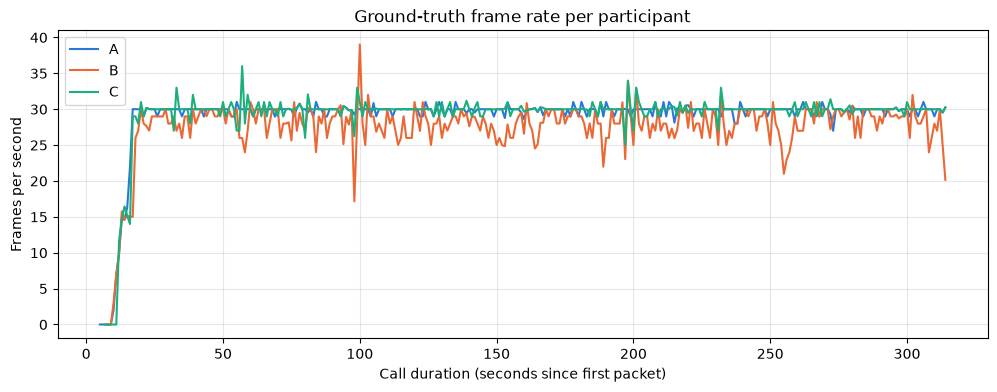

In [37]:
import matplotlib.pyplot as plt

first_packet = df['Time'].min()  # first packet in the whole trace

colors = {'A': '#2a78d6', 'B': '#eb6834', 'C': '#1baf7a'}
plt.figure(figsize=(12, 4))
for name, fps in [('A', FPS_A), ('B', FPS_B), ('C', FPS_C)]:
    start = (pd.Timestamp(fps['startTime']) - first_packet).total_seconds()
    seconds = [start + i for i in range(len(fps['values']))]
    plt.plot(seconds, fps['values'], label=name, color=colors[name], linewidth=1.5)

plt.xlabel('Call duration (seconds since first packet)')
plt.ylabel('Frames per second')
plt.title('Ground-truth frame rate per participant')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Step 3: QoE Prediction

**Rounding arrival time to the next integer:** Let's first define a time window in which we need to make our prediction. For keeping things consistent, let's assume that any packet that arrives in the interval $(t,\ t+1)$ seconds (boundaries not included) is assigned a window ID of $t+1$, where $t$ is an integer. If a packet arrives at exactly an integer time instant $t$, we assign $t$ as the window ID.

**Examples:**
- A packet arriving at time $t = 0.0$ seconds gets `window_id = 0`
- A packet arriving at time $t = 0.001$ seconds gets `window_id = 1`
- A packet arriving at time $t = 0.5$ seconds gets `window_id = 1`
- A packet arriving at time $t = 1.0$ seconds gets `window_id = 1`
- A packet arriving at time $t = 1.001$ seconds gets `window_id = 2`

**Note:** These arrival times are calculated relative to the first packet in the trace (regardless of whether it was a video packet or not).

Assuming the definition stated above, add a `window_id` column to your DataFrame.

In [38]:
import numpy as np

# seconds since the first packet in the whole trace
video['seconds'] = (video['Time'] - first_packet).dt.total_seconds()

# ceil rounds (t, t+1] up to t+1, and leaves exact integers alone
video['window_id'] = np.ceil(video['seconds']).astype(int)
video[['Time', 'seconds', 'window_id', 'Participant']].head()

,Time,seconds,window_id,Participant
751,2022-11-16 18:19:13.414399787,9.748889,10,B
752,2022-11-16 18:19:13.415101290,9.749591,10,B
753,2022-11-16 18:19:13.415101385,9.749591,10,B
799,2022-11-16 18:19:13.536586093,9.871075,10,A
800,2022-11-16 18:19:13.536695591,9.871185,10,A


Recall the content covered during the class on video quality inference. For each combination of the `window_id` and the `Participant`, calculate the features that would help you to predict frame rate. Some example features could be:

1. Packet size statistics (min, max, mean, std, median, etc.)
2. Inter-arrival Time statistics
3. Video Conferencing Application (VCA) semantic features

**Note:** Only use the features that are derived from the transport or the network layer. Do not use application layer features. You are encouraged to calculate these features by hand (without using `netml`).

In [39]:
video = video.sort_values('Time')

# inter-arrival time and size change vs. the previous packet in the same stream
video['iat'] = video.groupby('Participant')['seconds'].diff()
video['size_diff'] = video.groupby('Participant')['Length'].diff().abs()

# VCA semantic feature: guess frame boundaries from network-layer info only.
# packets of one frame arrive back-to-back with similar sizes, so a big gap
# or a size jump probably means a new frame started
video['new_frame'] = (video['iat'] > 0.01) | (video['size_diff'] > 5)

features = video.groupby(['Participant', 'window_id']).agg(
    num_packets=('Length', 'count'),
    total_bytes=('Length', 'sum'),
    size_mean=('Length', 'mean'),
    size_std=('Length', 'std'),
    size_min=('Length', 'min'),
    size_max=('Length', 'max'),
    size_median=('Length', 'median'),
    unique_sizes=('Length', 'nunique'),
    iat_mean=('iat', 'mean'),
    iat_std=('iat', 'std'),
    iat_max=('iat', 'max'),
    iat_median=('iat', 'median'),
    est_frames=('new_frame', 'sum'),
).reset_index().fillna(0)

features.head()

,Participant,window_id,num_packets,total_bytes,size_mean,size_std,size_min,size_max,size_median,unique_sizes,iat_mean,iat_std,iat_max,iat_median,est_frames
0,A,10,4,3872,968.000000,566.666863,118,1252,1251.0,3,0.007490,0.006438,0.011949,0.010413,3
1,A,11,11,9273,843.000000,363.697127,118,1249,785.0,10,0.093899,0.081720,0.254246,0.108725,9
2,A,12,14,10321,737.214286,317.426716,122,1089,689.0,11,0.076466,0.063008,0.168172,0.093842,10
3,A,13,21,20020,953.333333,157.299184,709,1255,923.0,19,0.045311,0.032561,0.106197,0.059196,15
4,A,14,32,27732,866.625000,206.342145,122,1209,885.0,23,0.032353,0.028764,0.079010,0.019056,19


Divide the feature matrix you obtained above into three parts (one for each participant). Add a `Ground Truth` column to the feature matrix for each participant. Use the dictionaries (`FPS_A`, `FPS_B`, and `FPS_C`) provided for Step 2 to assign values for this column. This column will contain ground-truth frame rate labels for each time window.

**Note:** Assume that the ground truth FPS recorded for the $k^{th}$ second considers all packets that arrived between the $(k-1)^{th}$ and the $k^{th}$ second, where $k$ is an integer (same round-up logic as before).

In [40]:
def add_ground_truth(name, fps):
    # which window the first ground-truth value lines up with
    # (A starts ~5s after the first packet, B and C ~7s)
    start = round((pd.Timestamp(fps['startTime']) - first_packet).total_seconds())
    gt = pd.DataFrame({
        'window_id': range(start, start + len(fps['values'])),
        'Ground Truth': fps['values'],
    })
    part = features[features['Participant'] == name]
    return part.merge(gt, on='window_id')  # keep windows that have both

feat_A = add_ground_truth('A', FPS_A)
feat_B = add_ground_truth('B', FPS_B)
feat_C = add_ground_truth('C', FPS_C)

print(len(feat_A), len(feat_B), len(feat_C))
feat_A.head()

305 305 303


,Participant,window_id,num_packets,total_bytes,size_mean,size_std,size_min,size_max,size_median,unique_sizes,iat_mean,iat_std,iat_max,iat_median,est_frames,Ground Truth
0,A,10,4,3872,968.000000,566.666863,118,1252,1251.0,3,0.007490,0.006438,0.011949,0.010413,3,2.007295
1,A,11,11,9273,843.000000,363.697127,118,1249,785.0,10,0.093899,0.081720,0.254246,0.108725,9,7.000881
2,A,12,14,10321,737.214286,317.426716,122,1089,689.0,11,0.076466,0.063008,0.168172,0.093842,10,9.836332
3,A,13,21,20020,953.333333,157.299184,709,1255,923.0,19,0.045311,0.032561,0.106197,0.059196,15,14.646171
4,A,14,32,27732,866.625000,206.342145,122,1209,885.0,23,0.032353,0.028764,0.079010,0.019056,19,14.620604


For each participant, make an 80-20 split in each matrix you obtained above. **Important:** Since this is time-series data, you should use a **temporal split** (not a random split). Use the first 80% of the time windows for training and the last 20% for testing. This simulates a realistic scenario where you train on historical data and predict future performance.

Experiment with different models like Decision Trees, Random Forests, SVMs or any other models of your choice. Use [mean_absolute_error](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_error.html) as your evaluation metric. Print the Mean Absolute Error separately for each participant for your best model.

In [41]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

feature_cols = [c for c in features.columns if c not in ['Participant', 'window_id']]

def temporal_split(d):
    d = d.sort_values('window_id')
    cut = int(len(d) * 0.8)  # first 80% train, last 20% test
    train, test = d.iloc[:cut], d.iloc[cut:]
    return train[feature_cols], test[feature_cols], train['Ground Truth'], test['Ground Truth']

models = {
    'Linear Regression': lambda: LinearRegression(),
    'Decision Tree': lambda: DecisionTreeRegressor(max_depth=5, random_state=0),
    'Random Forest': lambda: RandomForestRegressor(n_estimators=200, random_state=0),
    'SVM': lambda: make_pipeline(StandardScaler(), SVR()),
}

data = {'A': feat_A, 'B': feat_B, 'C': feat_C}
results = {}
for model_name, make_model in models.items():
    results[model_name] = {}
    for name, d in data.items():
        X_train, X_test, y_train, y_test = temporal_split(d)
        model = make_model().fit(X_train, y_train)
        results[model_name][name] = mean_absolute_error(y_test, model.predict(X_test))

results = pd.DataFrame(results).T
results['Average'] = results.mean(axis=1)
print(results.round(3))

best = results['Average'].idxmin()
print('\nBest model:', best)
for name in data:
    print(f'  Participant {name} MAE: {results.loc[best, name]:.3f}')

                       A      B      C  Average
Linear Regression  0.384  0.618  0.533    0.512
Decision Tree      0.389  0.740  0.321    0.483
Random Forest      0.352  0.694  0.355    0.467
SVM                0.310  0.647  0.327    0.428

Best model: SVM
  Participant A MAE: 0.310
  Participant B MAE: 0.647
  Participant C MAE: 0.327


**Bonus:**

1. Plot the feature importance scores for each participant's model. Do these plots agree across participants?
2. Train a single model that predicts the frame rate for all three participants. Compare its mean absolute error (MAE) with the average MAE for the three models you trained before.

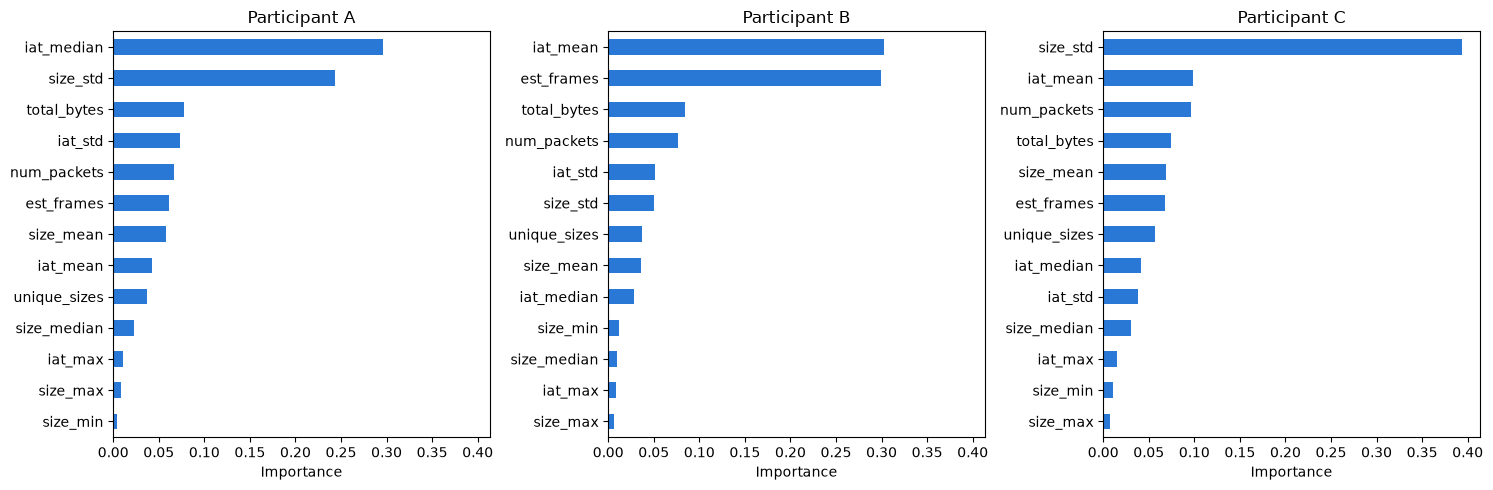

,A,B,C
iat_median,0.296,0.028,0.041
size_std,0.243,0.051,0.394
total_bytes,0.077,0.084,0.075
iat_std,0.074,0.051,0.038
num_packets,0.066,0.076,0.096
est_frames,0.061,0.299,0.068
size_mean,0.058,0.036,0.069
iat_mean,0.042,0.302,0.099
unique_sizes,0.037,0.037,0.057
size_median,0.023,0.009,0.030


In [42]:
# Bonus 1: feature importance per participant
# SVM doesn't give importances, so use a random forest here
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)
importances = {}
for ax, (name, d) in zip(axes, data.items()):
    X_train, X_test, y_train, y_test = temporal_split(d)
    rf = RandomForestRegressor(n_estimators=200, random_state=0).fit(X_train, y_train)
    imp = pd.Series(rf.feature_importances_, index=feature_cols)
    importances[name] = imp
    imp.sort_values().plot.barh(ax=ax, color='#2a78d6')
    ax.set_title(f'Participant {name}')
    ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

pd.DataFrame(importances).sort_values('A', ascending=False).round(3)

These plots do not agree across participants. Participant A's model uses iat_median and size_std the most, B uses iat_mean and est_frames, and C mostly uses size_std. Some features are useful for everyone (eg. total_bytes, num_packets), and some are useless for everyone (eg. size_min, size_max, iat_max). 

In [43]:
# Bonus 2: one model trained on all three participants
# use each participant's first 80% for training and last 20% for testing, then stack them
splits = [temporal_split(d) for d in data.values()]
X_train_all = pd.concat([s[0] for s in splits])
X_test_all = pd.concat([s[1] for s in splits])
y_train_all = pd.concat([s[2] for s in splits])
y_test_all = pd.concat([s[3] for s in splits])

single = make_pipeline(StandardScaler(), SVR()).fit(X_train_all, y_train_all)
single_mae = mean_absolute_error(y_test_all, single.predict(X_test_all))

print(f'Single model MAE:             {single_mae:.3f}')
print(f'Avg of per-participant MAEs:  {results.loc["SVM", "Average"]:.3f}')

# per-participant breakdown for the single model
for name, (_, X_test, _, y_test) in zip(data, splits):
    print(f'  {name}: {mean_absolute_error(y_test, single.predict(X_test)):.3f}')

Single model MAE:             0.450
Avg of per-participant MAEs:  0.428
  A: 0.345
  B: 0.617
  C: 0.389


The single model gets an MAE of 0.450, which is a bit worse than the 0.428 average of the three per-participant models. It does worse for A (0.345 vs 0.310) and C (0.389 vs 0.327), but slightly better for B (0.617 vs 0.647). So the separate models do slightly better overall.

Claude Code assisted me with implementation.